# HW05 (g) - Input impedance before and after cascading

Keep the actual cascade, remove the external source branch and inject 1 A AC into VinNode. Compare the real and imaginary input impedance with the first-stage result. Preserve measured differences instead of forcing agreement with the solution PDF.

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import re
import hw5_f as f
WORK = GENERATED / "g_rin_cascade.scs"
RESULTS = SIMULATION / "g"
FLOAT_RE = re.compile(r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?")


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def run_spectre():
    return __import__("runtime").run_spectre(WORK, RESULTS)

def build_g_netlist(w1_um, l1_nh, l2_nh, rp2_ohm, cp2_ff):
    # Build the exact physical cascade already used by part (f).
    f.build_netlist(
        w1_um,
        l1_nh,
        l2_nh,
        rp2_ohm,
        cp2_ff,
    )

    src = Path(f.WORK)

    if not src.exists():
        raise RuntimeError(
            f"Part (f) netlist was not generated: {src}"
        )

    text = src.read_text()

    # Keep the physical cascade but remove the two-tone source
    # and transient analysis beginning at VT1.
    marker = "\nVT1 ("

    if marker not in text:
        raise RuntimeError(
            "Could not find VT1 in f_cascade.scs; "
            "the hw5_f.py format may have changed."
        )

    circuit = text.split(
        marker,
        1,
    )[0]

    ac_tail = f'''
// ===========================================================
// HW5(g): small-signal input-impedance test
//
// 1-A AC current is injected INTO VinNode.
// Thus Zin = V(VinNode) / 1 A = V(VinNode).
//
// No 50-ohm source/termination is present during this test.
// ===========================================================

ITEST_G (0 VinNode) isource dc=0 type=sine mag=1 phase=0

simulatorOptions options temp=27 tnom=27 gmin=1e-12 reltol=1e-5

ac ac start=4G stop=8G lin=401

save VinNode Vout Vout2 S2
saveOptions options save=allpub
'''

    write_netlist(WORK, 
        circuit + ac_tail
    )

def parse_complex_value(line, name):
    rest = line.split(
        f'"{name}"',
        1,
    )[1]

    nums = [
        float(x)
        for x in FLOAT_RE.findall(rest)
    ]

    if not nums:
        raise ValueError(
            f"No numeric value found on line: {line}"
        )

    if len(nums) == 1:
        return complex(
            nums[0],
            0.0,
        )

    return complex(
        nums[0],
        nums[1],
    )

def read_zin():
    candidates = sorted(
        RESULTS.glob("ac*.ac")
    )

    if not candidates:
        candidates = sorted(
            p
            for p in RESULTS.iterdir()
            if p.is_file()
            and "ac" in p.name.lower()
        )

    if not candidates:
        raise RuntimeError(
            f"No AC result file found in {RESULTS}"
        )

    path = candidates[0]

    active = False
    current_freq = None
    data = []

    with path.open(
        errors="ignore"
    ) as fh:

        for raw in fh:
            line = raw.strip()

            if line == "VALUE":
                active = True
                continue

            if not active:
                continue

            if line.startswith('"freq"'):
                rest = line.split(
                    '"freq"',
                    1,
                )[1]

                nums = [
                    float(x)
                    for x in FLOAT_RE.findall(rest)
                ]

                if nums:
                    current_freq = nums[0]

            elif (
                current_freq is not None
                and line.startswith('"VinNode"')
            ):
                z = parse_complex_value(
                    line,
                    "VinNode",
                )

                data.append(
                    (
                        current_freq,
                        z,
                    )
                )

    if len(data) < 2:
        raise RuntimeError(
            f"Could not parse AC VinNode data from {path}"
        )

    data.sort(
        key=lambda x: x[0]
    )

    # 5.8 GHz lies exactly on this grid, but interpolate for robustness.
    for freq, z in data:
        if abs(freq - F0) <= 1.0:
            return z, path

    for (f1, z1), (f2, z2) in zip(
        data[:-1],
        data[1:],
    ):
        if f1 <= F0 <= f2:
            a = (
                (F0 - f1)
                / (f2 - f1)
            )

            z = (
                z1
                + a * (z2 - z1)
            )

            return z, path

    raise RuntimeError(
        "5.8 GHz lies outside parsed AC frequency range"
    )


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("g", {"g": {name: globals()[name] for name in []}})

    show_part("g")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    f.ATONE = require_part(load_meta(), "f")["outputs"]["selected_ATONE_Vpk"]
    if not META.exists():
        raise SystemExit(
            "hw5_meta.json not found."
        )

    meta = json.loads(
        META.read_text()
    )

    c = require_part(
        meta,
        "c",
    )

    e = require_part(
        meta,
        "e",
    )

    fmeta = require_part(
        meta,
        "f",
    )

    cout = c["outputs"]
    eout = e["outputs"]

    w1_um = float(
        cout["W1_um"]
    )

    l1_nh = float(
        cout["L1_nH"]
    )

    rin_before = float(
        cout["Rin_ohm"]
    )

    l2_nh = float(
        eout["L2_nH"]
    )

    rp2_ohm = float(
        eout["Rp_ohm"]
    )

    cp2_ff = float(
        eout["Cp_each_fF"]
    )

    print(
        "HW5(g): measure first-stage Rin "
        "after adding the real second stage"
    )

    print(
        f"Loaded (c): Rin before = "
        f"{rin_before:.6f} ohm"
    )

    print(
        f"Using W1={w1_um:.6f} um, "
        f"L1={l1_nh:.6f} nH, "
        f"L2={l2_nh:.6f} nH"
    )

    # Preserve the final part-(f) cascade-netlist configuration.
    selected_atone = float(
        fmeta.get("outputs", {}).get(
            "selected_ATONE_Vpk",
            f.ATONE,
        )
    )
    f.ATONE = selected_atone

    build_g_netlist(
        w1_um,
        l1_nh,
        l2_nh,
        rp2_ohm,
        cp2_ff,
    )

    run_spectre()

    zin_after, result_path = read_zin()

    rin_after = zin_after.real
    xin_after = zin_after.imag

    delta_r = (
        rin_after
        - rin_before
    )

    percent_change = (
        100.0
        * delta_r
        / rin_before
    )

    abs_zin = abs(
        zin_after
    )

    meta["parts"]["g"] = {
        "status": "complete",
        "completed_utc": f.now(),
        "depends_on": [
            "c",
            "e",
            "f",
        ],
        "method": (
            "AC small-signal simulation of the actual cascade; "
            "1-A current injected into VinNode with the external "
            "50-ohm source branch removed"
        ),
        "upstream": {
            "c_W1_um": w1_um,
            "c_L1_nH": l1_nh,
            "c_Rin_before_ohm": rin_before,
            "e_L2_nH": l2_nh,
            "f_status": fmeta["status"],
        },
        "inputs": {
            "frequency_Hz": F0,
            "test_current_A": 1.0,
            "source_termination_present": False,
            "topology": (
                "same cascade as part (f): Fig.1 dummy M2 removed "
                "and replaced by the actual Fig.3 second stage"
            ),
            "netlist": str(
                WORK
            ),
            "result_file": str(
                result_path
            ),
        },
        "outputs": {
            "Rin_before_second_stage_ohm": rin_before,
            "Rin_after_second_stage_ohm": rin_after,
            "Xin_after_second_stage_ohm": xin_after,
            "Zin_after_magnitude_ohm": abs_zin,
            "Rin_change_ohm": delta_r,
            "Rin_percent_change": percent_change,
        },
    }

    f.save_meta(
        meta
    )

    print()
    print(
        "===== HW5(g) RESULT ====="
    )

    print(
        f"Rin before stage 2     = "
        f"{rin_before:.6f} ohm"
    )

    print(
        f"Zin after stage 2      = "
        f"{rin_after:.6f} "
        f"{xin_after:+.6f}j ohm"
    )

    print(
        f"Rin after stage 2      = "
        f"{rin_after:.6f} ohm"
    )

    print(
        f"Delta Rin              = "
        f"{delta_r:+.6f} ohm"
    )

    print(
        f"Percent change         = "
        f"{percent_change:+.3f} %"
    )

    print()
    print(
        "Physical reason: replacing the dummy capacitive load "
        "with the actual second-stage input changes the impedance "
        "seen at the first-stage drain. Because the real MOSFET "
        "is not perfectly unilateral (finite ro and parasitic "
        "capacitances/feedback), that drain loading can be "
        "reflected back to the common-gate input impedance."
    )

    print()
    print(
        f"metadata -> {META}"
    )

    print(
        f"netlist  -> {WORK}"
    )
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    from psf import read_ascii
    freq, signals = read_ascii(find_result(RESULTS, "ac"), "freq", ["VinNode"], complex_values=True)
    save_curve("g_zin", frequency_Hz=freq, Zin=signals["VinNode"])


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| Rin_after_second_stage_ohm | 22.25792 |
| Rin_before_second_stage_ohm | 50.17933 |
| Rin_change_ohm | -27.9214 |
| Rin_percent_change | -55.64324 |
| Xin_after_second_stage_ohm | 93.4729 |
| Zin_after_magnitude_ohm | 96.08641 |

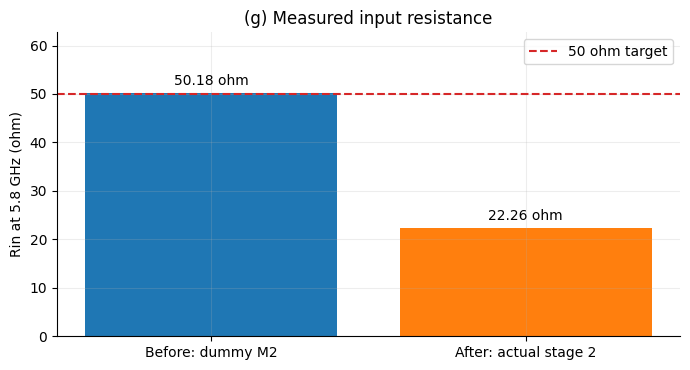

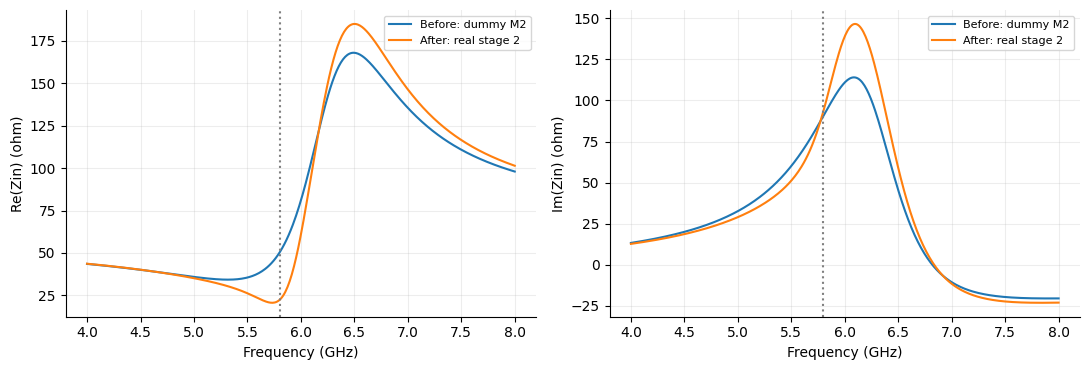

In [7]:
if EXECUTION_MODE == "review":
    show_part("g")